# Exact Green's function and self-energy: the 1D hydrogen atom

iDEA can construct the **exact** one-body Green's function $G(x,x';t)$ and **exact** exchange-correlation self-energy $\Sigma_{xc}(x,x';\omega)$ of an interacting state, from the exact eigenstates of the $(N-1)$- and $(N+1)$-electron systems (the Lehmann representation):

$$G_\sigma(x,x';z) = \sum_k \frac{d_k(x)\,d_k^*(x')}{z-\varepsilon_k},$$

with removal poles $\varepsilon_k = E^N_0 - E^{N-1}_k$ and Dyson orbitals $d_k(x) = \langle\Psi^{N-1}_k|\hat\psi_\sigma(x)|\Psi^N_0\rangle$, and addition poles $\varepsilon_k = E^{N+1}_k - E^N_0$ with $d_k(x) = \langle\Psi^N_0|\hat\psi_\sigma(x)|\Psi^{N+1}_k\rangle$. The self-energy is defined by Dyson's equation,

$$G^{-1}(z) = z - h_0 - v_h - \Sigma_{xc}(z), \qquad \Sigma_{xc}(z) = \Sigma_x + \sum_p \frac{r_p(x)\,r_p^*(x')}{z-\zeta_p},$$

and is also obtained exactly, in pole form. Its static part is the Fock operator of the exact density matrix.

Each sector is diagonalised in its Slater-determinant basis, either completely (`solver='dense'`) or with a block Krylov method seeded by $\hat\psi_\sigma(x)|\Psi\rangle$ and $\hat\psi_\sigma^\dagger(x)|\Psi\rangle$ (`solver='krylov'`), which keeps every sum rule exact. Here we use the simplest example, one electron bound by a softened nucleus, where the exact self-energy must cancel the electron's self-interaction exactly, something approximate self-energies such as *GW* do not do (self-screening).

## Reading $G$ and $\Sigma$

**The Green's function is the amplitude for an added electron, or hole, to propagate.** For $t>0$,

$$iG(x,x';t) = \langle\Psi_0|\hat\psi(x)\,e^{-i(\hat H-E_0)t}\,\hat\psi^\dagger(x')|\Psi_0\rangle.$$

That is, add an electron at $x'$, let the whole interacting system evolve for a time $t$, and project onto the state with an electron added at $x$. A column $G(\cdot,x_0;t)$ is therefore the wavefunction of an electron injected at $x_0$, dressed by the response of all the others. For $t<0$ the same holds for a hole: an electron removed, as in photoemission.

**At equal times, $G$ is the density matrix.** $G(x,x';t=0^-) = i\gamma(x,x')$, where $\gamma(x,x') = \langle\hat\psi^\dagger(x')\hat\psi(x)\rangle$. Its diagonal is the density $n(x)$. Off the diagonal, $\gamma(x,x')$ is the coherence between removing an electron at $x$ and at $x'$:
- it gives the kinetic and exchange energies and the momentum distribution;
- how fast it decays with $|x-x'|$ is a measure of nearsightedness.

**In frequency, the poles are spectroscopy and the residues are Dyson orbitals.**
- The poles $\varepsilon_k$ are the energies to remove an electron ($-I_k$, photoemission) or to add one (inverse photoemission).
- The residue $d_k(x)\,d_k^*(x')$ is the outer product of the Dyson orbital, the wavefunction of the electron removed or added. Its norm is the quasiparticle weight.
- The local spectral function $A(x,x;\omega) = \sum_k |d_k(x)|^2\,\delta(\omega-\varepsilon_k)$ is the local density of states for adding or removing an electron of energy $\omega$ at $x$. This is what a scanning tunnelling microscope measures.
- Integrating $A(x,x;\omega)$ up to $\mu$ gives $n(x)$. Integrating the full $A(x,x';\omega)$ over all $\omega$ gives $\delta(x-x')$, which is the completeness sum rule.
- Between the poles, $G(\omega)$ is a resolvent. In a gap it decays exponentially with $|x-x'|$ (tunnelling); in a continuum it oscillates.

**The self-energy is the potential felt by the added or removed electron.** The Dyson orbitals satisfy the quasiparticle equation exactly,

$$\left[h_0 + v_h\right]d_k(x) + \int \Sigma_{xc}(x,x';\varepsilon_k)\,d_k(x')\,dx' = \varepsilon_k\,d_k(x).$$

So $\Sigma_{xc}$ plays the role of the Kohn–Sham $v_{xc}$, but it is non-local (the element $(x,x')$ moves amplitude from $x'$ to $x$) and it depends on energy.
- $\Sigma_x(x,x') = -\gamma(x,x')\,v(x-x')$ is instantaneous. It is the Pauli and self-interaction correction, and it has the range of $\gamma$.
- The poles $\zeta_p$ of $\Sigma_c$ are the energies at which the added or removed electron can excite the rest of the system (two-particle–one-hole and two-hole–one-particle configurations, or shake-up). They produce satellites in $A(\omega)$ and take weight from the quasiparticle peak. The residues say how strongly an electron at $x$ couples into each channel.
- $\mathrm{Re}\,\Sigma_c$ is the relaxation and polarisation energy.
- $-\mathrm{Im}\,\Sigma_c^R(x,x;\omega) \ge 0$ acts like a local absorbing potential. It is the rate at which an electron added with energy $\omega$ leaks out of the one-particle channel, i.e. the inverse quasiparticle lifetime.
- In real time, $\Sigma_c(x,x';t)$ is a memory kernel. It is the amplitude for the electron to leave the one-particle channel at $x'$, by exciting the others, and to return at $x$ a time $t$ later. In *GW*, $\Sigma = iGW$: the electron interacts with the polarisation it left behind.

**For one spin-up electron**, as here, these become concrete.
- **Spin up.**
  - $G_\uparrow$ has a single removal pole, at $E_0$, with Dyson orbital $\phi$. So $G_\uparrow(t<0)$ is the fixed pattern $\phi(x)\phi(x')$ with a rotating phase.
  - A second spin-up electron forms a triplet, and Pauli exclusion keeps it out of $\phi$.
  - The exact $\Sigma_\uparrow$ satisfies $(v_h+\Sigma_x)\phi = 0$ and $\Sigma_c\phi = 0$: there is no self-interaction.
- **Spin down.**
  - $G_\downarrow$ has no removal part.
  - $\Sigma_{x,\downarrow} = 0$, so $\Sigma_\downarrow = \Sigma_{c,\downarrow}$ is pure correlation. It describes the incoming spin-down electron polarising the bound spin-up electron, which is what binds the H$^-$ ion.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import iDEA

x = np.linspace(-12, 12, 61)
s = iDEA.system.System(x, -1.0 / (abs(x) + 1.0), iDEA.interactions.softened_interaction(x), electrons="u")
state = iDEA.methods.interacting.solve(s, k=0)
green = iDEA.methods.interacting.green_function(s, state)
print(f"E0 = {state.energy:.8f}, mu = {green.mu:.6f}")
print({key: f"{value:.1e}" for key, value in green.info.items() if key != "sectors"})

iDEA.methods.interacting.solve: solving eigenproblem on CPU...
iDEA.methods.interacting.green_function: adding a spin-up electron, sector dimension 1830...


iDEA.methods.interacting.green_function: adding a spin-down electron, sector dimension 3721...


E0 = -0.51083377, mu = -0.278439
{'rayleigh_residual': '8.4e-15', 'up_completeness_error': '1.1e-15', 'up_first_moment_error': '6.9e-14', 'down_completeness_error': '1.1e-15', 'down_first_moment_error': '6.5e-14', 'galitskii_migdal_error': '2.2e-16'}


The `info` dictionary records the exact sum rules: completeness of the Dyson orbitals, the first moment (the static self-energy equals the Fock operator of the exact density matrix), the Galitskii–Migdal energy and the Rayleigh-quotient residual of the state. All are at machine precision.

For one electron there is a single removal pole, at $E_0 = -I$ (the vacuum has zero energy), with the occupied orbital as its Dyson orbital. The addition poles are the two-electron states: triplets in the up channel and singlets (including the weakly bound H$^-$ ion) in the down channel.

removal pole: [-0.51083377]  E0: -0.510833768331594


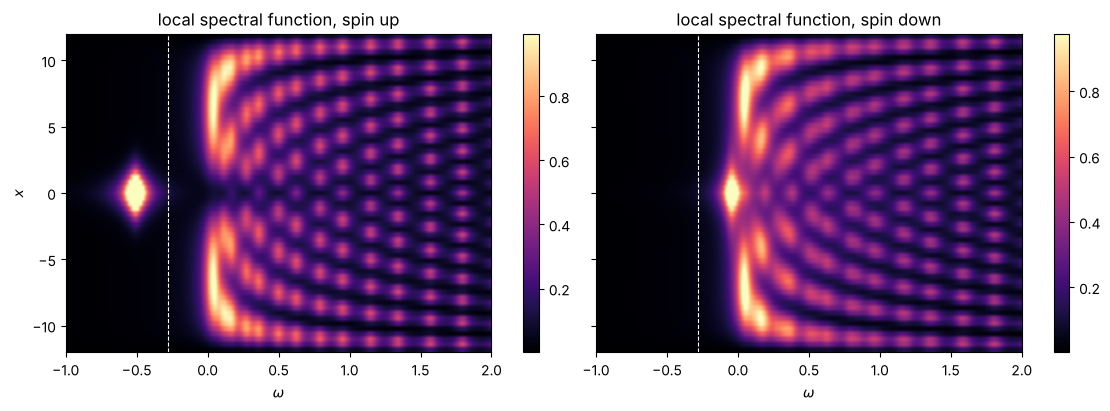

In [2]:
removal = green.up.occupations > 0
print("removal pole:", green.up.energies[removal], " E0:", state.energy)

omega = np.linspace(-1.0, 2.0, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, spin in zip(axes, ("up", "down")):
    A = iDEA.observables.spectral_function(s, green, omega, eta=0.05, spin=spin, diagonal=True)
    image = ax.imshow(A.T, origin="lower", aspect="auto", extent=[omega[0], omega[-1], x[0], x[-1]], cmap="magma", vmax=np.percentile(A, 99.5))
    ax.axvline(green.mu, color="w", ls="--", lw=0.8)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"local spectral function, spin {spin}")
    fig.colorbar(image, ax=ax)
axes[0].set_ylabel("$x$")
plt.show()

## An electron injected at the nucleus

A column of $G(x,x';t>0)$ is the amplitude of an electron injected at $x'$. Inject one at the nucleus, $x'=0$. The point source is band-limited with `cutoff=0.5`, which keeps energies within about 0.5 of $\mu$; this is not exact (see *Snapshots and videos* below). The two spin channels behave very differently:
- **Spin up.** Pauli exclusion projects the occupied orbital $\phi$ out of the injected electron. That leaves a hole where $\phi$ is, so the amplitude starts in two lobes either side of the nucleus. With no bound triplet state, the electron flies away, and returns only after reflecting off the edges of the box.
- **Spin down.** The electron can bind to form H$^-$, the addition pole below zero. Part of its amplitude stays at the atom while the rest radiates away.

H- addition pole: [-0.04604442]


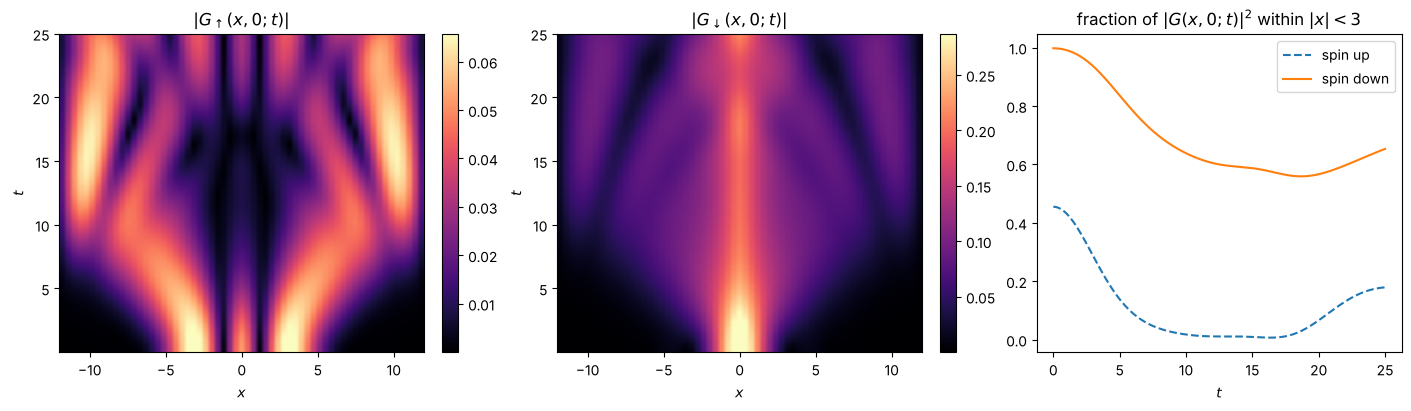

In [3]:
# t = 0 is taken as 0^- (the density matrix), so start just after it.
t = np.linspace(1e-6, 25.0, 251)
i0 = np.argmin(abs(x))
near = abs(x) < 3
bound = (green.down.occupations == 0) & (green.down.energies < 0)
print("H- addition pole:", green.down.energies[bound])

arrows = {"up": r"\uparrow", "down": r"\downarrow"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, spin, ls in zip(axes, ("up", "down"), ("--", "-")):
    G = iDEA.observables.green_function(s, green, t=t, spin=spin, cutoff=0.5)[:, :, i0]
    image = ax.imshow(abs(G), origin="lower", aspect="auto", extent=[x[0], x[-1], t[0], t[-1]], cmap="magma", vmax=np.percentile(abs(G), 99.5))
    ax.set_xlabel("$x$")
    ax.set_ylabel("$t$")
    ax.set_title(f"$|G_{arrows[spin]}(x,0;t)|$")
    fig.colorbar(image, ax=ax)
    fraction = np.sum(abs(G[:, near]) ** 2, axis=1) / np.sum(abs(G) ** 2, axis=1)
    axes[2].plot(t, fraction, ls, label=f"spin {spin}")
axes[2].set_xlabel("$t$")
axes[2].set_title(r"fraction of $|G(x,0;t)|^2$ within $|x|<3$")
axes[2].legend()
plt.show()

## Self-interaction

For one electron, $(v_h + \Sigma_{xc}(z))\,\phi = 0$ for the occupied orbital $\phi$ at every frequency: the exchange part cancels the Hartree potential and the correlation part annihilates $\phi$. Every correlation pole is particle-like (character $+1$).

In [4]:
phi = green.up.orbitals[:, removal][:, 0]
sigma_x = iDEA.observables.self_energy(s, green, part="x")
nu = np.array([0.0, 0.5, 2.0])
sigma_c = iDEA.observables.self_energy(s, green, nu=nu, part="c")
print("|(v_h + Sigma_x) phi| =", np.linalg.norm(green.v_h * phi + sigma_x @ phi * s.dx))
print("|Sigma_c(i nu) phi|   =", [np.linalg.norm(S @ phi * s.dx) for S in sigma_c])
print("self-energy pole characters:", np.unique(np.round(green.up.sigma_character, 12)), np.unique(np.round(green.down.sigma_character, 12)))

|(v_h + Sigma_x) phi| = 2.4648822501899503e-14
|Sigma_c(i nu) phi|   = [np.float64(1.7565447551775337e-17), np.float64(1.5952585641840722e-17), np.float64(1.1509903294065483e-17)]
self-energy pole characters: [1.] [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1.]


## Comparison with *GW*

The same quantities from G$_0$W$_0$, GW$_0$ and self-consistent *GW* (`iDEA.methods.mbpt`) on the imaginary axis. Each method's occupied orbital is used. *GW* leaves a self-screening residual and over-binds the electron.

G0W0  E = -0.517064   (exact -0.510834)


GW0   E = -0.516250   (exact -0.510834)


GW    E = -0.516269   (exact -0.510834)


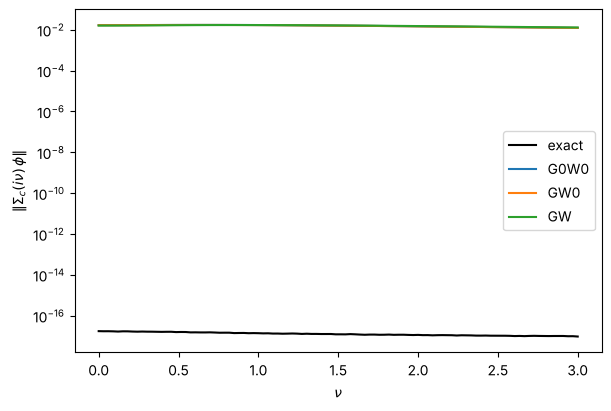

In [5]:
nu = np.linspace(0.0, 3.0, 100)
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
exact = [np.linalg.norm(S @ phi) * s.dx for S in iDEA.observables.self_energy(s, green, nu=nu, part="c")]
ax.semilogy(nu, np.maximum(exact, 1e-18), "k-", label="exact")
gw = {}
for mode in ("G0W0", "GW0", "GW"):
    gw[mode] = iDEA.methods.mbpt.solve(s, mode=mode, silent=True)
    phi_gw = gw[mode].up.orbitals[:, gw[mode].up.occupations > 0][:, 0]
    residual = [np.linalg.norm(S @ phi_gw) * s.dx for S in iDEA.observables.self_energy(s, gw[mode], nu=nu, part="c")]
    ax.semilogy(nu, residual, label=mode)
    print(f"{mode:5s} E = {gw[mode].energy:.6f}   (exact {state.energy:.6f})")
ax.set_xlabel(r"$\nu$")
ax.set_ylabel(r"$\Vert\Sigma_c(i\nu)\,\phi\Vert$")
ax.legend()
plt.show()

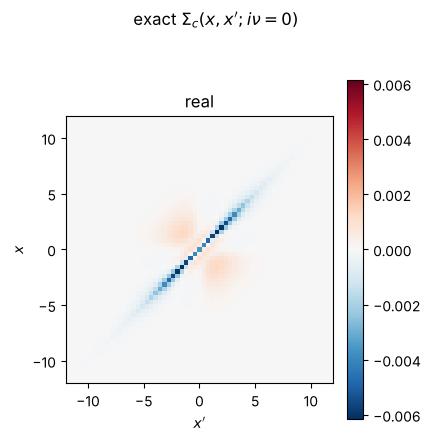

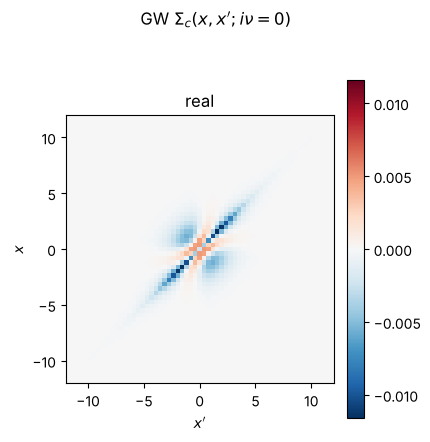

In [6]:
fig = iDEA.plotting.plot_two_point(x, iDEA.observables.self_energy(s, green, nu=np.array([0.0]), part="c")[0], parts=("real",), title=r"exact $\Sigma_c(x,x';i\nu=0)$")
display(fig)
fig = iDEA.plotting.plot_two_point(x, iDEA.observables.self_energy(s, gw["GW"], nu=np.array([0.0]), part="c")[0], parts=("real",), title=r"GW $\Sigma_c(x,x';i\nu=0)$")
display(fig)

## Snapshots and videos

`iDEA.plotting.plot_two_point` draws a snapshot of any two-point quantity, and `iDEA.plotting.animate` (with the wrappers `animate_green_function` and `animate_self_energy`) animates it over real time $t$, real frequency $\omega$ or imaginary frequency $\nu$, saving `.mp4` (requires ffmpeg) or `.gif` files. In a notebook the returned animation can be shown inline with `IPython.display.HTML(animation.to_jshtml())`.

On the real-time axis the Green's function of a point-like added electron contains every grid energy, which dominates the picture; the `cutoff` argument applies a smooth energy filter about $\mu$ to band-limit such videos (the result is then no longer exact).

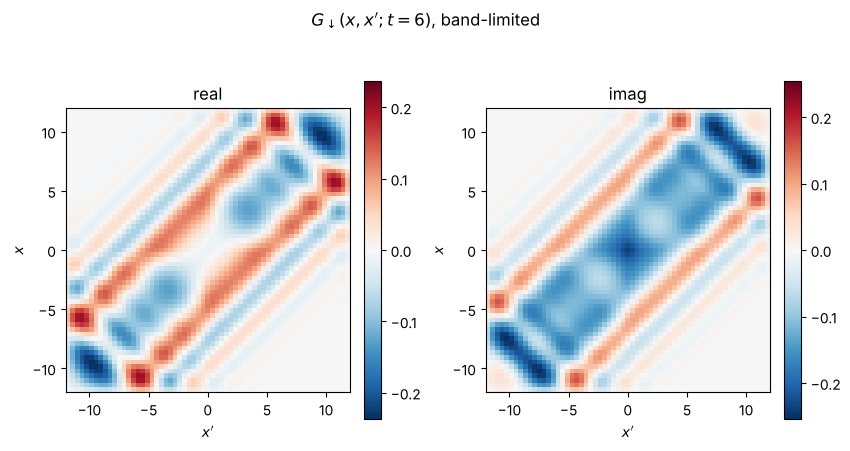

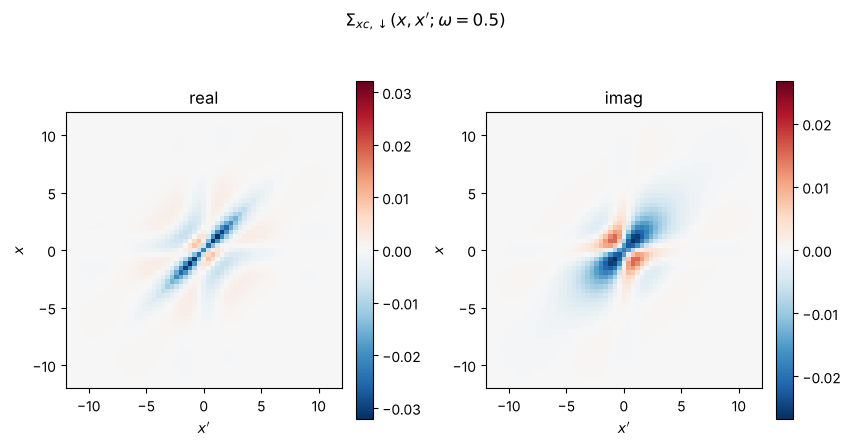

In [7]:
t = np.array([6.0])
G = iDEA.observables.green_function(s, green, t=t, spin="down", cutoff=1.0)[0]
display(iDEA.plotting.plot_two_point(x, G, title=r"$G_\downarrow(x,x';t=6)$, band-limited"))
sigma = iDEA.observables.self_energy(s, green, omega=np.array([0.5]), spin="down")[0]
display(iDEA.plotting.plot_two_point(x, sigma, title=r"$\Sigma_{xc,\downarrow}(x,x';\omega=0.5)$"))

In [8]:
# Videos are written to files (set SAVE = True to render them; this takes a minute or two).
SAVE = False
if SAVE:
    iDEA.plotting.animate_green_function(s, green, t=np.linspace(0, 30, 150), spin="down", cutoff=1.0, demodulate=True, file_name="G_down_t.mp4")
    iDEA.plotting.animate_self_energy(s, green, omega=np.linspace(-1, 2, 150), spin="down", file_name="Sigma_xc_down_omega.mp4")
    iDEA.plotting.animate_self_energy(s, green, t=np.linspace(0, 30, 150), spin="down", cutoff=1.0, file_name="Sigma_c_down_t.mp4")

For production-quality grids, and the full set of videos and figures, see `tutorial/green_function_hydrogen.py` (with `--gpu` to diagonalise the sectors on a GPU).